In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import os

In [2]:
#### CONSTANTES FÍSICAS 
## Vamos a trabajar en años
# T12 = 5730.0
# Lambda = np.log(2)/T12

T12 = np.log(2)
Lambda = np.log(2) / T12

n0 = np.array([10**2, 10**3, 10**4, 10**5, 10**6, 10**7])  # número de núcleos a tiempo 0

t = 5       # tiempo total que vamos a simular
dt = 0.05    # intervalo de tiempo
u = int(t/dt)  # número de intervalos
tiempos = np.arange(u + 1) * dt


# Posición del tiempo de vida media
pos_t12 = int(round(T12 / dt))

num_simulaciones = 300

plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 16,
    "axes.labelsize": 18,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 18,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})

In [3]:
inicio = time.perf_counter()

M = np.zeros((num_simulaciones, u + 1))

q_step = np.exp(-Lambda * dt)

media_exp = np.zeros(len(n0))
desviacion_exp = np.zeros(len(n0))
incertidumbre_rel = np.zeros(len(n0))

for k in range(len(n0)):
    n_0 = n0[k]

    for i in range(num_simulaciones):
        N = n_0
        M[i, 0] = N

        for j in range(1, u + 1):
            N = np.random.binomial(N, q_step)
            M[i, j] = N

    media_exp[k] = np.mean(M[:, pos_t12])
    desviacion_exp[k] = np.std(M[:, pos_t12], ddof=1)
    incertidumbre_rel[k] = desviacion_exp[k] / media_exp[k]

fin = time.perf_counter()

np.savetxt("Media_experimental_para_cada_número_de_núcleos.txt", media_exp)
np.savetxt("Desviación_experimental_para_cada_número_de_núcleos.txt", desviacion_exp)
np.savetxt("Incertidumbre_relativa_para_cada_número_de_núcleos.txt", incertidumbre_rel)
print(f"Tiempo de ejecución: {fin - inicio} segundos")


Tiempo de ejecución: 0.28236977299820865 segundos


Exponente para sigma_N vs N0: 0.506
Exponente para sigma_N / media vs N0: -0.494


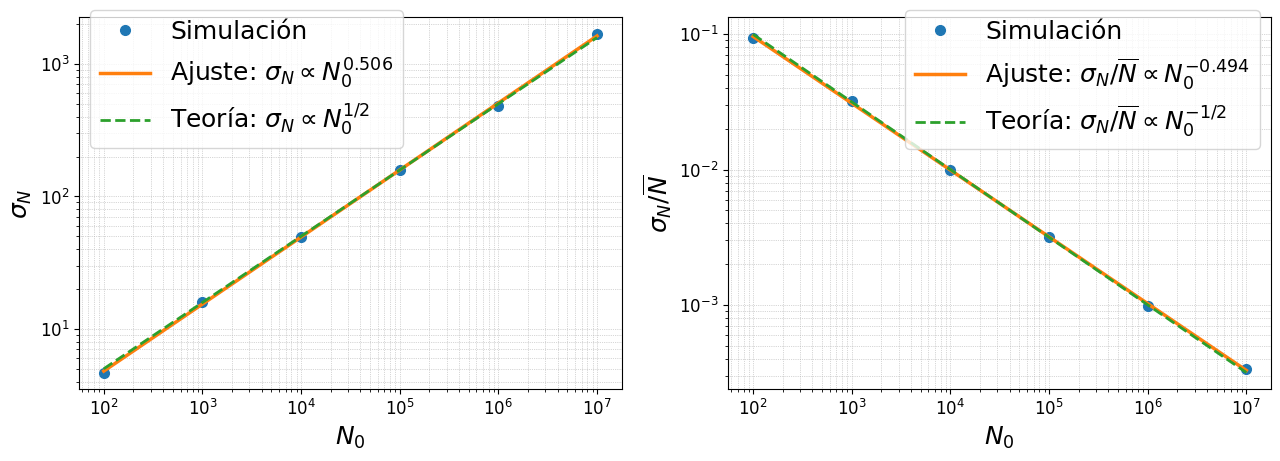

In [4]:
# ============================================================
# AJUSTES LOG-LOG
# ============================================================

pendiente_sigma, ordenada_sigma = np.polyfit(
    np.log(n0),
    np.log(desviacion_exp),
    1
)

pendiente_rel, ordenada_rel = np.polyfit(
    np.log(n0),
    np.log(incertidumbre_rel),
    1
)

print(f"Exponente para sigma_N vs N0: {pendiente_sigma:.3f}")
print(f"Exponente para sigma_N / media vs N0: {pendiente_rel:.3f}")


# ============================================================
# CURVAS DE AJUSTE
# ============================================================

n0_suave = np.logspace(
    np.log10(min(n0)),
    np.log10(max(n0)),
    300
)

ajuste_sigma = (
    np.exp(ordenada_sigma)
    * n0_suave**pendiente_sigma
)

ajuste_rel = (
    np.exp(ordenada_rel)
    * n0_suave**pendiente_rel
)

# Curvas teóricas en t = t_{1/2}
sigma_teorica = 0.5 * np.sqrt(n0_suave)
rel_teorica = 1 / np.sqrt(n0_suave)


# ============================================================
# FIGURA CONJUNTA
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.8)
)


# ------------------------------------------------------------
# PANEL IZQUIERDO: DESVIACIÓN TÍPICA
# ------------------------------------------------------------

axes[0].loglog(
    n0,
    desviacion_exp,
    "o",
    markersize=7,
    label="Simulación"
)

axes[0].loglog(
    n0_suave,
    ajuste_sigma,
    "-",
    linewidth=2.5,
    label=(
        rf"Ajuste: $\sigma_N \propto "
        rf"N_0^{{{pendiente_sigma:.3f}}}$"
    )
)

axes[0].loglog(
    n0_suave,
    sigma_teorica,
    "--",
    linewidth=2,
    label=r"Teoría: $\sigma_N \propto N_0^{1/2}$"
)

axes[0].set_xlabel(
    r"$N_0$",
    fontsize=18
)

axes[0].set_ylabel(
    r"$\sigma_N$",
    fontsize=18
)

axes[0].grid(
    True,
    which="both",
    linestyle=":",
    linewidth=0.5
)

axes[0].legend(
    fontsize=18,
    frameon=True,
    loc="upper left",
    bbox_to_anchor=(0.02, 1.02),
    borderaxespad=0
)



# ------------------------------------------------------------
# PANEL DERECHO: DESVIACIÓN TÍPICA RELATIVA
# ------------------------------------------------------------

axes[1].loglog(
    n0,
    incertidumbre_rel,
    "o",
    markersize=7,
    label="Simulación"
)

axes[1].loglog(
    n0_suave,
    ajuste_rel,
    "-",
    linewidth=2.5,
    label=(
        rf"Ajuste: $\sigma_N/\overline{{N}} "
        rf"\propto N_0^{{{pendiente_rel:.3f}}}$"
    )
)

axes[1].loglog(
    n0_suave,
    rel_teorica,
    "--",
    linewidth=2,
    label=(
        r"Teoría: $\sigma_N/\overline{N} "
        r"\propto N_0^{-1/2}$"
    )
)

axes[1].set_xlabel(
    r"$N_0$",
    fontsize=18
)

axes[1].set_ylabel(
    r"$\sigma_N/\overline{N}$",
    fontsize=18
)

axes[1].grid(
    True,
    which="both",
    linestyle=":",
    linewidth=0.5
)

axes[1].legend(
    fontsize=18,
    frameon=True,
    loc="upper right",
    bbox_to_anchor=(0.98, 1.02),
    borderaxespad=0
)

# ============================================================
# AJUSTE Y GUARDADO
# ============================================================

fig.tight_layout()

fig.savefig(
    "dependencia_incertidumbre_N0.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()